# Analyze: what each company gets paid for, and who pays it

Uses `data/category_totals.csv`, the net dollars DoD obligated to each company in each fiscal year from 2020 through 2026. Fiscal 2026 is incomplete because DoD contract data is published on about a 90-day delay.

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

totals = pd.read_csv("data/category_totals.csv", dtype={"code": str})
psc = totals[totals["grouping"] == "psc"].copy()
branch = totals[totals["grouping"] == "branch"].copy()

company_dollars = psc.groupby("company")["amount"].sum().sort_values(ascending=False)
print((company_dollars / 1e9).round(2).to_string())

company
Lockheed Martin     425.04
RTX                 205.47
General Dynamics    182.76
Boeing              171.58
Northrop Grumman    102.22
Palantir              3.46
Anduril               2.02
Scale AI              0.12
Shield AI             0.04


## Dollars by year

In [2]:
by_year = psc.pivot_table(index="company", columns="fiscal_year", values="amount", aggfunc="sum")
by_year = by_year.loc[company_dollars.index]
print((by_year / 1e9).round(2).to_string())

fiscal_year        2020   2021   2022   2023   2024   2025   2026
company                                                          
Lockheed Martin   76.66  41.19  48.01  72.76  52.90  76.61  56.91
RTX               27.22  20.46  25.73  31.55  27.97  36.66  35.88
General Dynamics  24.35  20.15  26.16  28.72  24.09  33.96  25.33
Boeing            24.20  25.27  17.16  24.22  24.75  23.38  32.60
Northrop Grumman  12.46  13.01  13.89  16.14  19.10  13.70  13.92
Palantir           0.14   0.08   0.23   0.18   0.36   0.79   1.68
Anduril            0.03   0.01   0.11   0.16   0.58   0.46   0.66
Scale AI           0.02   0.00   0.04   0.02   0.03   0.01   0.01
Shield AI          0.00   0.00   0.02   0.01   0.00   0.01   0.01


## Group the product and service codes

There are hundreds of PSC codes, so they are grouped by hand into six buckets. Codes that start with a letter are services and R&D, and codes that start with a number are products. In the 70s, only `70` and a `7` followed by a letter are IT; the other 70s are things like furniture.

In [3]:
AIRCRAFT = ["15", "16", "17", "28", "29"]
WEAPONS_SHIPS_VEHICLES = ["10", "11", "12", "13", "14", "18", "19", "20", "23", "24", "25"]

BUCKETS = ["Aircraft and engines", "Weapons, ships, vehicles", "Other hardware",
           "R&D", "IT and software", "Other services"]


def psc_bucket(code):
    """Sort one PSC code into one of the six buckets."""
    if code[0] == "A":
        return "R&D"
    if code[0] == "D" or code[:2] == "70" or (code[0] == "7" and code[1].isalpha()):
        return "IT and software"
    if code[0].isalpha():
        return "Other services"
    if code[:2] in AIRCRAFT:
        return "Aircraft and engines"
    if code[:2] in WEAPONS_SHIPS_VEHICLES:
        return "Weapons, ships, vehicles"
    return "Other hardware"


psc["bucket"] = psc["code"].apply(psc_bucket)

# Spot check: the biggest codes in each bucket
top_codes = psc.groupby(["bucket", "code", "name"])["amount"].sum().reset_index()
top_codes = top_codes.sort_values("amount", ascending=False).groupby("bucket").head(3).sort_values("bucket")
top_codes["amount"] = (top_codes["amount"] / 1e9).round(1)
print(top_codes.to_string(index=False))

                  bucket code                                                                                         name  amount
    Aircraft and engines 1510                                                                         AIRCRAFT, FIXED WING   216.2
    Aircraft and engines 1520                                                                        AIRCRAFT, ROTARY WING    38.9
    Aircraft and engines 2840                         GAS TURBINES AND JET ENGINES, AIRCRAFT, PRIME MOVING; AND COMPONENTS    34.9
         IT and software DA01       IT AND TELECOM - BUSINESS APPLICATION/APPLICATION DEVELOPMENT SUPPORT SERVICES (LABOR)     2.0
         IT and software DA10          IT AND TELECOM - BUSINESS APPLICATION/APPLICATION DEVELOPMENT SOFTWARE AS A SERVICE     1.6
         IT and software D399                                              IT AND TELECOM- OTHER IT AND TELECOMMUNICATIONS     1.4
          Other hardware 5840                                                      

## Share of each company's dollars by bucket

In [4]:
bucket_dollars = psc.pivot_table(index="company", columns="bucket", values="amount", aggfunc="sum", fill_value=0)
bucket_dollars = bucket_dollars.loc[company_dollars.index, BUCKETS]
bucket_share = bucket_dollars.div(bucket_dollars.sum(axis=1), axis=0) * 100
print(bucket_share.round(1).to_string())

bucket            Aircraft and engines  Weapons, ships, vehicles  Other hardware   R&D  IT and software  Other services
company                                                                                                                
Lockheed Martin                   45.7                      24.9             6.4  11.4              0.3            11.2
RTX                               19.5                      36.2            18.1   8.1              1.9            16.3
General Dynamics                   0.1                      78.1             3.1   2.8              3.3            12.6
Boeing                            57.2                       9.8             9.3   4.2              0.5            19.0
Northrop Grumman                  14.4                      12.9            16.7  29.6              1.8            24.5
Palantir                           0.0                       0.0             1.2  14.0             81.0             3.8
Anduril                            8.5  

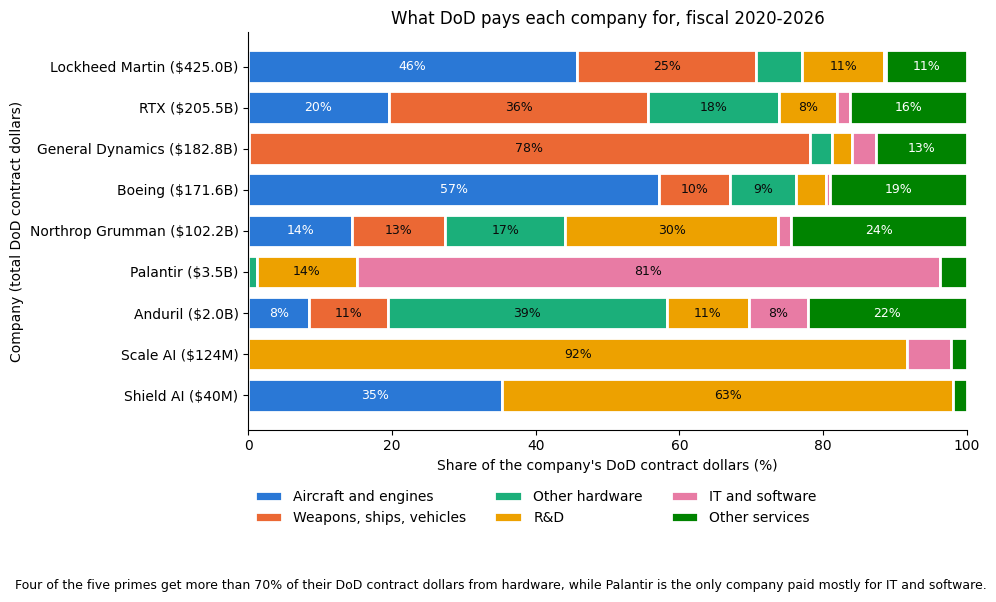

In [5]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
CAPTION_1 = "Four of the five primes get more than 70% of their DoD contract dollars from hardware, while Palantir is the only company paid mostly for IT and software."

def dollar_label(dollars):
    """Format dollars in billions, or millions for the smallest companies."""
    return f"${dollars / 1e9:,.1f}B" if dollars >= 1e9 else f"${dollars / 1e6:,.0f}M"


labels = [f"{company} ({dollar_label(dollars)})" for company, dollars in company_dollars.items()]

fig, ax = plt.subplots(figsize=(10, 6))
left = pd.Series(0.0, index=bucket_share.index)
for bucket, color in zip(BUCKETS, COLORS):
    bars = ax.barh(labels, bucket_share[bucket], left=left, color=color, edgecolor="white", linewidth=2, label=bucket)
    text_color = "white" if color in ["#2a78d6", "#008300"] else "#0b0b0b"
    for bar, share in zip(bars, bucket_share[bucket]):
        if share >= 8:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + bar.get_height() / 2,
                    f"{share:.0f}%", ha="center", va="center", color=text_color, fontsize=9)
    left = left + bucket_share[bucket]

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("What DoD pays each company for, fiscal 2020-2026")
ax.set_xlabel("Share of the company's DoD contract dollars (%)")
ax.set_ylabel("Company (total DoD contract dollars)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="", ncol=3, loc="upper center", bbox_to_anchor=(0.4, -0.12), frameon=False)
fig.text(0.02, 0.01, CAPTION_1, fontsize=9, wrap=True)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.savefig("figures/category_mix.png", dpi=200)
plt.show()

## Share of each company's dollars by branch

In [6]:
MAIN_BRANCHES = {
    "Department of the Navy": "Navy",
    "Department of the Air Force": "Air Force",
    "Department of the Army": "Army",
    "Missile Defense Agency": "Missile Defense Agency",
    "U.S. Special Operations Command": "Special Operations",
}
BRANCH_ORDER = list(MAIN_BRANCHES.values()) + ["Other DoD"]

branch["branch"] = branch["name"].map(MAIN_BRANCHES).fillna("Other DoD")
branch_dollars = branch.pivot_table(index="company", columns="branch", values="amount", aggfunc="sum", fill_value=0)
branch_dollars = branch_dollars.loc[company_dollars.index, BRANCH_ORDER]
branch_share = branch_dollars.div(branch_dollars.sum(axis=1), axis=0) * 100
print(branch_share.round(1).to_string())

branch            Navy  Air Force  Army  Missile Defense Agency  Special Operations  Other DoD
company                                                                                       
Lockheed Martin   48.7       20.0  22.0                     6.2                 1.4        1.7
RTX               41.1       21.8  19.3                     8.9                 0.4        8.4
General Dynamics  63.3        3.5  30.5                    -0.0                 0.1        2.6
Boeing            26.3       50.2  13.6                     2.6                 2.4        4.8
Northrop Grumman  28.4       41.5  18.7                     6.1                 0.0        5.3
Palantir           2.7       22.0  72.1                     0.4                 1.7        1.1
Anduril           19.8       14.3  10.2                     0.0                55.4        0.3
Scale AI           0.0        8.9  87.1                     0.0                 0.0        4.0
Shield AI         37.1       61.0   0.0           

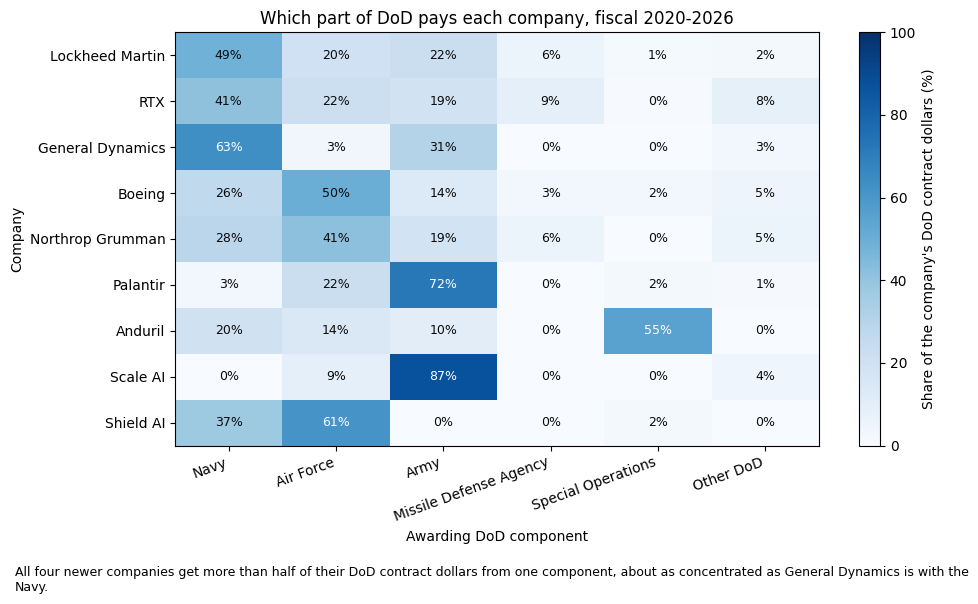

In [7]:
CAPTION_2 = "All four newer companies get more than half of their DoD contract dollars from one component, about as concentrated as General Dynamics is with the Navy."

fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(branch_share, cmap="Blues", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(BRANCH_ORDER)), BRANCH_ORDER, rotation=20, ha="right")
ax.set_yticks(range(len(branch_share)), branch_share.index)
for row, company in enumerate(branch_share.index):
    for column, name in enumerate(BRANCH_ORDER):
        share = branch_share.loc[company, name]
        ax.text(column, row, f"{round(share)}%", ha="center", va="center",
                color="white" if share >= 55 else "#0b0b0b", fontsize=9)

ax.set_title("Which part of DoD pays each company, fiscal 2020-2026")
ax.set_xlabel("Awarding DoD component")
ax.set_ylabel("Company")
fig.colorbar(image, ax=ax, label="Share of the company's DoD contract dollars (%)")
fig.text(0.02, 0.01, CAPTION_2, fontsize=9, wrap=True)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig("figures/branch_share.png", dpi=200)
plt.show()

## Concentration

The concentration score is the share of a company's dollars in its single biggest bucket or branch. Higher means more dependent on one thing.

In [8]:
concentration = pd.DataFrame({
    "total_billions": (company_dollars / 1e9).round(2),
    "top_bucket": bucket_share.idxmax(axis=1),
    "top_bucket_share": bucket_share.max(axis=1).round(1),
    "top_branch": branch_share.idxmax(axis=1),
    "top_branch_share": branch_share.max(axis=1).round(1),
})
print(concentration.to_string())

                  total_billions                top_bucket  top_bucket_share          top_branch  top_branch_share
company                                                                                                           
Lockheed Martin           425.04      Aircraft and engines              45.7                Navy              48.7
RTX                       205.47  Weapons, ships, vehicles              36.2                Navy              41.1
General Dynamics          182.76  Weapons, ships, vehicles              78.1                Navy              63.3
Boeing                    171.58      Aircraft and engines              57.2           Air Force              50.2
Northrop Grumman          102.22                       R&D              29.6           Air Force              41.5
Palantir                    3.46           IT and software              81.0                Army              72.1
Anduril                     2.02            Other hardware              38.9  Sp

## Who holds the IT and software dollars

The proposal said it would be a surprise if the primes held more of these dollars than the newer companies.

In [9]:
it_dollars = bucket_dollars["IT and software"].sort_values(ascending=False)
it_table = pd.DataFrame({
    "it_millions": (it_dollars / 1e6).round(1),
    "share_of_company": bucket_share.loc[it_dollars.index, "IT and software"].round(1),
})
print(it_table.to_string())

primes = ["Lockheed Martin", "RTX", "Boeing", "General Dynamics", "Northrop Grumman"]
newer = ["Palantir", "Anduril", "Shield AI", "Scale AI"]
print("Primes:", round(it_dollars[primes].sum() / 1e9, 2), "billion")
print("Newer companies:", round(it_dollars[newer].sum() / 1e9, 2), "billion")

                  it_millions  share_of_company
company                                        
General Dynamics       6022.5               3.3
RTX                    3820.1               1.9
Palantir               2800.9              81.0
Northrop Grumman       1881.8               1.8
Lockheed Martin        1267.8               0.3
Boeing                  856.4               0.5
Anduril                 166.6               8.2
Scale AI                  7.6               6.1
Shield AI                 0.0               0.0
Primes: 13.85 billion
Newer companies: 2.97 billion
